# UCS420 Lab Assignment 9 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [1]:
ROLL_NO = 1024160025
NAME = "Amanjot Kaur Sidhu"

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [2]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [3]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [4]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024160025   Name: Amanjot Kaur Sidhu   Fingerprint: 8E41E8BD   Tickets: 12

Ticket_ID                                                                             Ticket_Text
      T01                       Laptop was working yesterday during the lab. It worked yesterday.
      T02                              The Wi-Fi is showing an error. I have tried several times!
      T03                                               The printer won't print; it isn't jammed.
      T04                                                   I tried again... still no response!!!
      T05                              The Python is showing an error. Is there another solution?
      T06                            The student portal is showing an error. It worked yesterday.
      T07          E-mail is not working after restarting the system. I have tried several times!
      T08                                                             The file is 95.5% uploaded.
      T09                   

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [6]:
# Q1. Preprocessing pipeline

from IPython.display import display
import pandas as pd

# Process every ticket using the official function
processed = {}

for _, row in df.iterrows():
    ticket_id = row["Ticket_ID"]
    ticket_text = row["Ticket_Text"]

    processed[ticket_id] = process_ticket(ticket_text)

# Create the summary table
summary_rows = []

for _, row in df.iterrows():
    ticket_id = row["Ticket_ID"]
    result = processed[ticket_id]

    summary_rows.append({
        "Ticket_ID": ticket_id,
        "Sentences": len(result["sentences"]),
        "Tokens": len(result["tokens"]),
        "Punctuation Tokens": len(result["punct"]),
        "Stopwords": len(result["stops"]),
        "Unique Tokens": len(set(result["tokens"])),
        "Final Tokens": len(result["final"])
    })

summary_df = pd.DataFrame(summary_rows)

# Create the TOTAL row
total_row = {
    "Ticket_ID": "TOTAL",
    "Sentences": summary_df["Sentences"].sum(),
    "Tokens": summary_df["Tokens"].sum(),
    "Punctuation Tokens": summary_df["Punctuation Tokens"].sum(),
    "Stopwords": summary_df["Stopwords"].sum(),
    # Unique words across the entire corpus, not the sum of per-ticket uniques
    "Unique Tokens": len(set(
        token
        for result in processed.values()
        for token in result["tokens"]
    )),
    "Final Tokens": summary_df["Final Tokens"].sum()
}

summary_df = pd.concat(
    [summary_df, pd.DataFrame([total_row])],
    ignore_index=True
)

display(summary_df)

# Display the details of one selected ticket
selected_id = FOCUS[0]
selected = processed[selected_id]

print("\nSelected Ticket ID:", selected_id)
print("Ticket Text:", df.loc[df["Ticket_ID"] == selected_id,
                             "Ticket_Text"].iloc[0])

print("\nAll lowercase tokens:")
print(selected["tokens"])

print("\nPunctuation tokens:")
print(selected["punct"])

print("\nStopwords:")
print(selected["stops"])

print("\nFinal tokens:")
print(selected["final"])

,Ticket_ID,Sentences,Tokens,Punctuation Tokens,Stopwords,Unique Tokens,Final Tokens
0,T01,2,12,2,4,10,6
1,T02,2,13,2,5,13,6
2,T03,1,11,2,3,10,6
3,T04,2,10,4,3,8,3
4,T05,2,12,2,5,11,5
5,T06,2,12,2,4,11,6
6,T07,2,15,2,6,15,7
7,T08,1,7,2,2,7,3
8,T09,2,14,2,7,14,5
9,T10,2,18,2,8,16,8



Selected Ticket ID: T07
Ticket Text: E-mail is not working after restarting the system. I have tried several times!

All lowercase tokens:
['e-mail', 'is', 'not', 'working', 'after', 'restarting', 'the', 'system', '.', 'i', 'have', 'tried', 'several', 'times', '!']

Punctuation tokens:
['.', '!']

Stopwords:
['is', 'not', 'after', 'the', 'i', 'have']

Final tokens:
['e-mail', 'working', 'restarting', 'system', 'tried', 'several', 'times']


**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

The non-word fragments in the final tokens are mainly n't (from contractions such as won't, isn't, and couldn't) and wo (the remaining fragment of won't). They come from word_tokenize, which splits some contractions into separate pieces; the pipeline removes stopwords and punctuation but does not rejoin contraction fragments, so fragments can remain in the final list.



---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [10]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

# Q2. Regular expressions

import re

# All raw ticket texts
raw_tickets = df["Ticket_Text"].tolist()

# The assignment's test lines
test_lines = TEST_LINES

# Combine both sets so the patterns are tested on both
all_texts = raw_tickets + test_lines

# Extract words containing more than 5 letters
long_word_pattern = r"\b[A-Za-z]{6,}\b"

# Extract numbers, including decimals, versions, comma-separated numbers,
# and hexadecimal error codes
number_pattern = (
    r"(?<![\w.])"
    r"(?:0[xX][0-9A-Fa-f]+"
    r"|\d{1,3}(?:,\d{3})+(?:\.\d+)?"
    r"|\d+(?:\.\d+)+"
    r"|\d+)"
    r"(?![\w.])"
)

# Extract words beginning with a capital letter
capitalized_pattern = r"\b[A-Z][a-zA-Z]*\b"

# Extract words beginning with a vowel
vowel_pattern = r"\b[AEIOUaeiou][a-zA-Z]*\b"

# Patterns for email addresses, URLs and phone numbers
email_pattern = r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b"

url_pattern = r"""(?:https?://|www\.)[^\s<>"']+"""

phone_pattern = (
    r"(?<!\w)"
    r"(?:\+\d{1,3}[- ]?)?"
    r"(?:\d{5}[- ]\d{5}|\d{4}[- ]\d{3}[- ]\d{4}|\d{10})"
    r"(?!\w)"
)

# Extraction results
for i, text in enumerate(all_texts, start=1):
    print(f"\nText {i}: {text}")

    print("Words longer than 5 letters:",
          re.findall(long_word_pattern, text))

    print("Numbers:",
          re.findall(number_pattern, text))

    print("Capitalized words:",
          re.findall(capitalized_pattern, text))

    print("Words beginning with a vowel:",
          re.findall(vowel_pattern, text))


# Replace URLs while preserving punctuation that follows a URL
def replace_url(match):
    url = match.group(0)
    trailing = ""

    while url and url[-1] in ".,!?;:)":
        trailing = url[-1] + trailing
        url = url[:-1]

    return "<URL>" + trailing


# Replacement results
for i, text in enumerate(all_texts, start=1):
    cleaned = re.sub(email_pattern, "<EMAIL>", text)
    cleaned = re.sub(url_pattern, replace_url, cleaned)
    cleaned = re.sub(phone_pattern, "<PHONE>", cleaned)

    print(f"\nText {i} after replacements:")
    print(cleaned)

    sentence_initial_words = []

for text in raw_tickets:
    for sentence in sent_tokenize(text):
        match = re.search(r"\b[A-Z][a-zA-Z]*\b", sentence)
        if match:
            sentence_initial_words.append(match.group(0))

print("Capitalized words at sentence beginnings:",
      len(sentence_initial_words))
print("Examples:", sentence_initial_words)


Text 1: Laptop was working yesterday during the lab. It worked yesterday.
Words longer than 5 letters: ['Laptop', 'working', 'yesterday', 'during', 'worked', 'yesterday']
Numbers: []
Capitalized words: ['Laptop', 'It']
Words beginning with a vowel: ['It']

Text 2: The Wi-Fi is showing an error. I have tried several times!
Words longer than 5 letters: ['showing', 'several']
Numbers: []
Capitalized words: ['The', 'Wi', 'Fi', 'I']
Words beginning with a vowel: ['is', 'an', 'error', 'I']

Text 3: The printer won't print; it isn't jammed.
Words longer than 5 letters: ['printer', 'jammed']
Numbers: []
Capitalized words: ['The']
Words beginning with a vowel: ['it', 'isn']

Text 4: I tried again... still no response!!!
Words longer than 5 letters: ['response']
Numbers: []
Capitalized words: ['I']
Words beginning with a vowel: ['I', 'again']

Text 5: The Python is showing an error. Is there another solution?
Words longer than 5 letters: ['Python', 'showing', 'another', 'solution']
Numbers: []


**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

 There are 20 capitalized-token occurrences that appear at sentence beginnings in this dataset. Two additional capitalized occurrences, Wi-Fi and Python, occur within sentences and are retained with capitals because of their spelling/context rather than sentence position. This count refers to the extracted capitalized occurrences, not distinct word types.

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [11]:
# Q3. Custom tokenization

from nltk.tokenize import RegexpTokenizer, word_tokenize

# One RegexpTokenizer pattern with alternatives for different token types
token_pattern = (
    r"""(?:https?://|www\.)[^\s<>"']*[^\s<>"'.,!?;:)]"""
    r"""|[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}"""
    r"""|(?:\+\d{1,3}[- ]?)?(?:\d{5}[- ]\d{5}|\d{4}[- ]\d{3}[- ]\d{4}|\d{10})"""
    r"""|\d+(?:\.\d+)+"""
    r"""|[A-Za-z]+(?:-[A-Za-z]+)+"""
    r"""|[A-Za-z]+(?:['’][A-Za-z]+)+"""
    r"""|[A-Za-z]+"""
    r"""|[^\w\s]"""
)

tokenizer = RegexpTokenizer(token_pattern)


def my_tokenize(text):
    """Tokenize text while preserving special formats as single tokens."""
    return tokenizer.tokenize(text)


# Test the tokenizer on TEST_LINES
print("CUSTOM TOKENIZER ON TEST_LINES")

for i, line in enumerate(TEST_LINES, start=1):
    print(f"\nTest line {i}:")
    print(my_tokenize(line))


# Compare both tokenizers on TEST_LINES
print("\nCOMPARISON ON TEST_LINES")

for i, line in enumerate(TEST_LINES, start=1):
    custom_tokens = my_tokenize(line)
    standard_tokens = word_tokenize(line)

    print(f"\nTest line {i}")
    print("my_tokenize():", custom_tokens)
    print("word_tokenize():", standard_tokens)
    print("Different:", custom_tokens != standard_tokens)


# Run both tokenizers on every generated ticket
different_tickets = []

print("\nCOMPARISON ON GENERATED TICKETS")

for _, row in df.iterrows():
    ticket_id = row["Ticket_ID"]
    text = row["Ticket_Text"]

    custom_tokens = my_tokenize(text)
    standard_tokens = word_tokenize(text)

    if custom_tokens != standard_tokens:
        different_tickets.append(ticket_id)

    print(f"\n{ticket_id}: {text}")
    print("Custom:", custom_tokens)
    print("Standard:", standard_tokens)
    print("Different:", custom_tokens != standard_tokens)

print("\nNumber of tickets tokenized differently:",
      len(different_tickets))
print("Ticket IDs:", different_tickets)

CUSTOM TOKENIZER ON TEST_LINES

Test line 1:
['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']

Test line 2:
['Call', '+91 98765 43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', ',', '.']

Test line 3:
['The', 'state-of-the-art', 'lab', "isn't", 'open', ';', 'log-in', 'at', '5.30', 'p', '.', 'm', '.', "didn't", 'work', '.']

COMPARISON ON TEST_LINES

Test line 1
my_tokenize(): ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']
word_tokenize(): ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']
Different: True

Test line 2
my_tokenize(): ['Call', '+91 98765 43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 

**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

12 out of 12 tickets are tokenized differently by my_tokenize and NLTK's word_tokenize. The custom tokenizer keeps selected contractions, hyphenated forms, decimals/versions, URLs, emails, and some phone formats together, while word_tokenize splits several of these into multiple tokens. The exact differences depend on the regex pattern.

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [14]:
# Q4. Stemming and lemmatization

import re
import nltk
import pandas as pd

from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer
from nltk.stem import WordNetLemmatizer
from nltk.corpus import wordnet

# Collect unique final tokens from the official preprocessing pipeline
unique_final_tokens = sorted({
    token
    for result in processed.values()
    for token in result["final"]
})

# Initialize the stemmers and lemmatizer
porter = PorterStemmer()
lancaster = LancasterStemmer()
lemmatizer = WordNetLemmatizer()


# Choose a RegexpStemmer suffix after inspecting the dataset
suffix_candidates = [r"ing$", r"ed$", r"s$"]

suffix_counts = {
    suffix: sum(
        1 for word in unique_final_tokens
        if re.search(suffix, word)
    )
    for suffix in suffix_candidates
}

chosen_suffix = max(suffix_counts, key=suffix_counts.get)

# Show which words support the selected suffix
suffix_examples = [
    word for word in unique_final_tokens
    if re.search(chosen_suffix, word)
]

regexp_stemmer = RegexpStemmer(chosen_suffix)
print("Suffix counts:", suffix_counts)
print("Chosen suffix:", chosen_suffix)
print("Words matching the suffix:", suffix_examples)


# Convert Penn Treebank POS tags to WordNet POS tags
def get_wordnet_pos(treebank_tag):
    if treebank_tag.startswith("J"):
        return wordnet.ADJ
    elif treebank_tag.startswith("V"):
        return wordnet.VERB
    elif treebank_tag.startswith("N"):
        return wordnet.NOUN
    elif treebank_tag.startswith("R"):
        return wordnet.ADV
    else:
        return wordnet.NOUN


# Tag the unique tokens
pos_tags = nltk.pos_tag(unique_final_tokens)

pos_lookup = {
    word: get_wordnet_pos(tag)
    for word, tag in pos_tags
}


# Compare all four methods
comparison_rows = []

for word in unique_final_tokens:
    porter_result = porter.stem(word)
    lancaster_result = lancaster.stem(word)
    regexp_result = regexp_stemmer.stem(word)

    pos = pos_lookup[word]
    lemma_result = lemmatizer.lemmatize(word, pos=pos)

    results = [
        porter_result,
        lancaster_result,
        regexp_result,
        lemma_result
    ]

    # Keep only words for which at least two methods differ
    if len(set(results)) > 1:
        comparison_rows.append({
            "Original Word": word,
            "Porter Stem": porter_result,
            "Lancaster Stem": lancaster_result,
            "Regexp Stem": regexp_result,
            "POS-aware Lemma": lemma_result,
            "POS Tag": pos
        })


comparison_df = pd.DataFrame(comparison_rows)

print("\nWords where the methods produce different results:")

if not comparison_df.empty:
    display(comparison_df)
else:
    print("No differences found for the current dataset.")

print("\nTotal unique final tokens:", len(unique_final_tokens))
print("Words with differing outputs:", len(comparison_df))

Suffix counts: {'ing$': 4, 'ed$': 4, 's$': 1}
Chosen suffix: ing$
Words matching the suffix: ['resetting', 'restarting', 'showing', 'working']

Words where the methods produce different results:


,Original Word,Porter Stem,Lancaster Stem,Regexp Stem,POS-aware Lemma,POS Tag
0,another,anoth,anoth,another,another,n
1,error,error,er,error,error,n
2,file,file,fil,file,file,n
3,jammed,jam,jam,jammed,jam,v
4,please,pleas,pleas,please,please,v
5,portal,portal,port,portal,portal,a
6,printer,printer,print,printer,printer,n
7,projector,projector,project,projector,projector,n
8,resetting,reset,reset,resett,reset,v
9,resolve,resolv,resolv,resolve,resolve,a



Total unique final tokens: 42
Words with differing outputs: 22


**Observe:** Give one over-stemming and one under-stemming example from your table.

An over-stemming example is Lancaster reducing student → stud, which removes too much of the word. An under-stemming example is the custom RegexpStemmer producing jammed → jamm, which leaves an awkward stem instead of reducing it to jam.

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

Corpus statistics:


,Total Tokens,Unique Tokens,TTR
S1: All Tokens,147.0,71.0,0.4830
S2: Without Punctuation,121.0,64.0,0.5289
S3: Final Tokens,66.0,42.0,0.6364
S4: Porter Stemmed,66.0,41.0,0.6212



Top 10 words in S1:
[('.', 14), ('the', 10), ('is', 8), ('i', 6), ('!', 6), ('it', 4), ('showing', 4), ('an', 4), ('error', 4), ('tried', 4)]

Top 10 words in S3:
[('showing', 4), ('error', 4), ('tried', 4), ('yesterday', 3), ('several', 3), ('times', 3), ('printer', 3), ("n't", 3), ('laptop', 2), ('working', 2)]


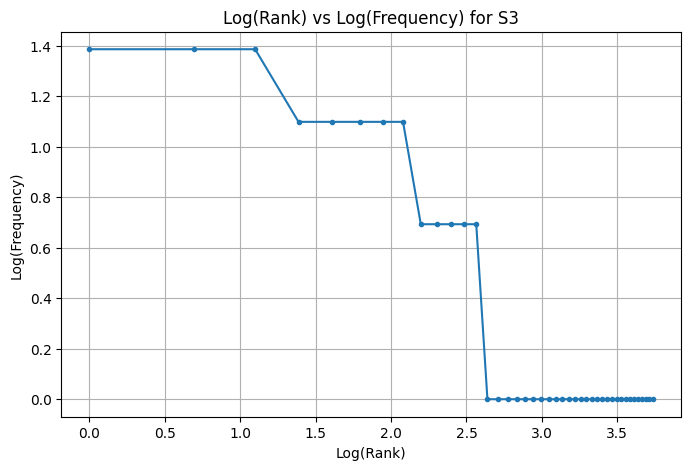


Top 5 bigrams in S1:
[(('is', 'showing'), 4), (('showing', 'an'), 4), (('an', 'error'), 4), (('.', 'i'), 4), (('error', '.'), 3)]

Top 5 bigrams in S3:
[(('showing', 'error'), 4), (('tried', 'several'), 3), (('several', 'times'), 3), (('worked', 'yesterday'), 2), (('restarting', 'system'), 2)]


In [13]:
# Q5. Corpus statistics

import math
import matplotlib.pyplot as plt
from collections import Counter
from nltk.util import bigrams

# S1: All tokens, including punctuation and stopwords
S1 = [
    token
    for result in processed.values()
    for token in result["tokens"]
]

# S2: Tokens with punctuation removed
S2 = [
    token
    for result in processed.values()
    for token in result["tokens"]
    if not is_punct(token)
]

# S3: Final tokens after removing punctuation and stopwords
S3 = [
    token
    for result in processed.values()
    for token in result["final"]
]

# S4: S3 after Porter stemming
S4 = [porter.stem(token) for token in S3]


# Calculate corpus statistics
def corpus_statistics(tokens):
    total_tokens = len(tokens)
    unique_tokens = len(set(tokens))

    ttr = (
        unique_tokens / total_tokens
        if total_tokens > 0
        else 0
    )

    return {
        "Total Tokens": total_tokens,
        "Unique Tokens": unique_tokens,
        "TTR": round(ttr, 4)
    }


statistics = pd.DataFrame({
    "S1: All Tokens": corpus_statistics(S1),
    "S2: Without Punctuation": corpus_statistics(S2),
    "S3: Final Tokens": corpus_statistics(S3),
    "S4: Porter Stemmed": corpus_statistics(S4)
}).T

print("Corpus statistics:")
display(statistics)


# Top 10 most frequent tokens
print("\nTop 10 words in S1:")
print(Counter(S1).most_common(10))

print("\nTop 10 words in S3:")
print(Counter(S3).most_common(10))


# Plot log(rank) versus log(frequency) for S3
frequency_counts = Counter(S3).most_common()

if frequency_counts:
    frequencies = [frequency for word, frequency in frequency_counts]
    ranks = list(range(1, len(frequencies) + 1))

    log_ranks = [math.log(rank) for rank in ranks]
    log_frequencies = [math.log(freq) for freq in frequencies]

    plt.figure(figsize=(8, 5))
    plt.plot(log_ranks, log_frequencies, marker="o", markersize=3)
    plt.xlabel("Log(Rank)")
    plt.ylabel("Log(Frequency)")
    plt.title("Log(Rank) vs Log(Frequency) for S3")
    plt.grid(True)
    plt.show()
else:
    print("S3 is empty, so the plot cannot be generated.")


# Top 5 bigrams for S1 and S3
# A bigram is a pair of consecutive tokens.
S1_bigrams = Counter(bigrams(S1))
S3_bigrams = Counter(bigrams(S3))

print("\nTop 5 bigrams in S1:")
print(S1_bigrams.most_common(5))

print("\nTop 5 bigrams in S3:")
print(S3_bigrams.most_common(5))

**Observe:** Why does TTR change from S1 to S4 in your data?

TTR is the number of unique tokens divided by the total number of tokens. From S1 to S3, TTR rises from 0.483 to 0.632 because punctuation and stopwords are removed, reducing the total token count proportionally more than the number of distinct tokens. From S3 to S4, Porter stemming merges some related forms (unique tokens fall from 36 to 35) while the total remains 57, so TTR decreases slightly to 0.614.